# Week 10: Pandas pt. 2
**Name**: Isabelle Sakelaris \ 
**Date**: Nov. 2, 2026

In [2]:
# first we will import vis libraries and their related components
import pandas as pd
import json                                  # to parse the GeoJSON files
import re                                    # regular expressions for the word cloud
import matplotlib.pyplot as plt              # to display the word clouds
import plotly.express as px                  # the quick way to make interactive charts and maps ("px")
import pydeck as pdk                         # 3D maps
from IPython.display import HTML, IFrame     # to show web pages and HTML inside the notebook instead of markdown
from wordcloud import STOPWORDS, WordCloud   # word clouds

## Visualizing poll data
There are two files with recent polling data for the midtersm from the *NYT*. First we will load them as a dataframe. 

In [3]:
# reading the CSV files into dataframes
house = pd.read_csv("house_average_recent.csv")
senate = pd.read_csv("senate_average_recent.csv")

# len() of a table is its number of rows: one row per district, and one row per state
print(len(house), "House districts,", len(senate), "Senate states")

# .head() shows the first five rows, so we can see what the columns look like
house.head()

114 House districts, 29 Senate states


,id,state,district,dem,rep,margin,polls,latest,days_old
0,AK-1,AK,1,5.8,45.8,-40.1,1,2026-10-30,1
1,AL-2,AL,2,45.0,49.5,-4.5,1,2026-10-25,6
2,AR-2,AR,2,48.0,52.0,-4.0,1,2026-10-14,17
3,AZ-1,AZ,1,49.4,45.0,4.4,1,2026-10-28,3
4,AZ-2,AZ,2,50.0,48.0,2.0,1,2026-10-14,17


In [4]:
# the Senate table has the same columns, except there's no district number
senate.head()

,state,dem,rep,margin,polls,latest,days_old
0,AK,48.7,47.1,1.6,2,2026-10-30,2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8
2,AR,39.0,55.0,-16.0,1,2026-10-28,4
3,FL,43.6,49.3,-5.7,7,2026-10-30,2
4,GA,53.9,43.8,10.1,3,2026-10-23,9


Right now, third-party and undecided voters are not included in the data. We understand these numbers to be percentages that *would* add up to 100, but we need to fill in the remainder.

Other = 100 - dem - rep

In [5]:
# round(1) = round the number to a single decimal point.
senate["other"] = (100 - senate["dem"] - senate["rep"]).clip(lower=0).round(1) # clip lower = 0 is making sure we can't get a negative number, which is and edge case from averaging/rouding 

senate.head()

,state,dem,rep,margin,polls,latest,days_old,other
0,AK,48.7,47.1,1.6,2,2026-10-30,2,4.2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8,12.7
2,AR,39.0,55.0,-16.0,1,2026-10-28,4,6.0
3,FL,43.6,49.3,-5.7,7,2026-10-30,2,7.1
4,GA,53.9,43.8,10.1,3,2026-10-23,9,2.3


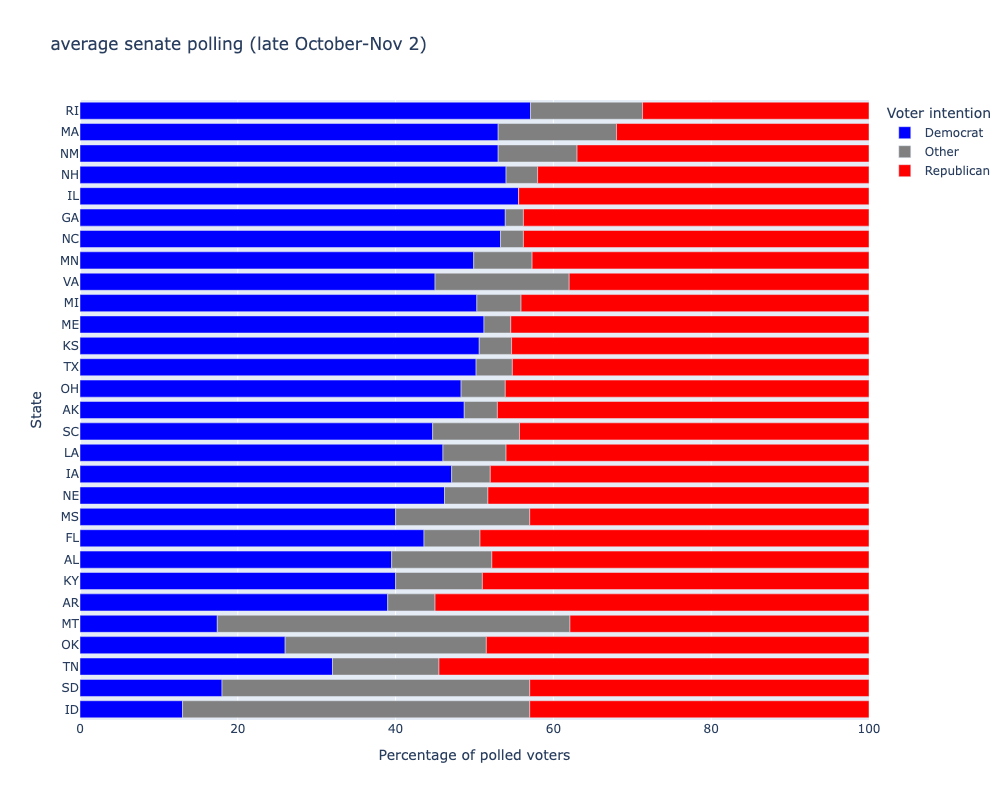

In [6]:
party_names = {"dem":"Democrat", "other":"Other", "rep":"Republican"}
colors = {"Democrat":"blue", "Other":"grey", "Republican":"red"}
senate_sorted = senate.sort_values("margin").rename(columns=party_names)

fig = px.bar(
    senate_sorted, #the data we're dealing with should be the first arg
    x=["Democrat", "Other", "Republican"], 
    y="state",
    orientation="h", #horizontal bars
    color_discrete_map=colors, #directly map colors to columns
    labels={"value":"Percent", "state":"State"},
    hover_data= {"polls":True,"latest":True}, # selecting extra data to display when you hover over the bars,
    height=800, # height of the graph (don't make it too small bc there's a lot of data)
    title="average senate polling (late October-Nov 2)"
)
fig.update_layout(
    legend_title_text="Voter intention",
    xaxis_title="Percentage of polled voters",
    xaxis_range=[0,100] #stretches teh data across the full width of the graph
)

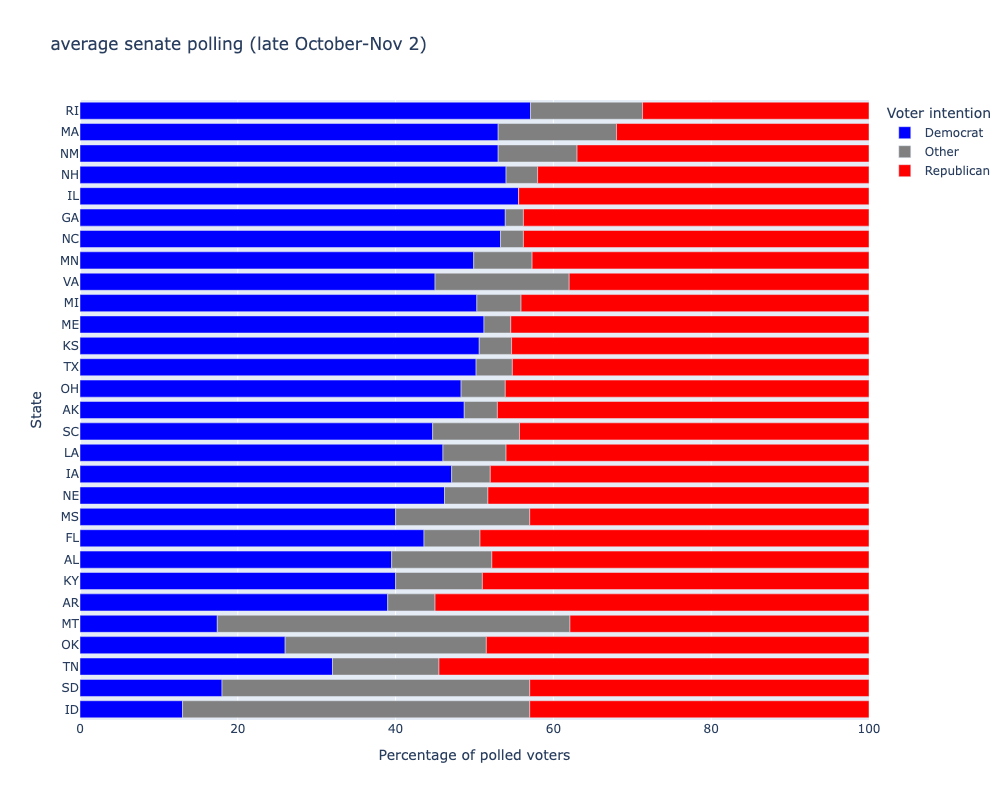

In [7]:
fig.update_layout(
    legend_title_text="Voter intention",
    xaxis_title="Percentage of polled voters",
    xaxis_range=[0,100] #stretches teh data across the full width of the graph
)

## Generating a map of the senate races
Now we will create a map version! We can combine the data with the shape of the states (already included in plotly).

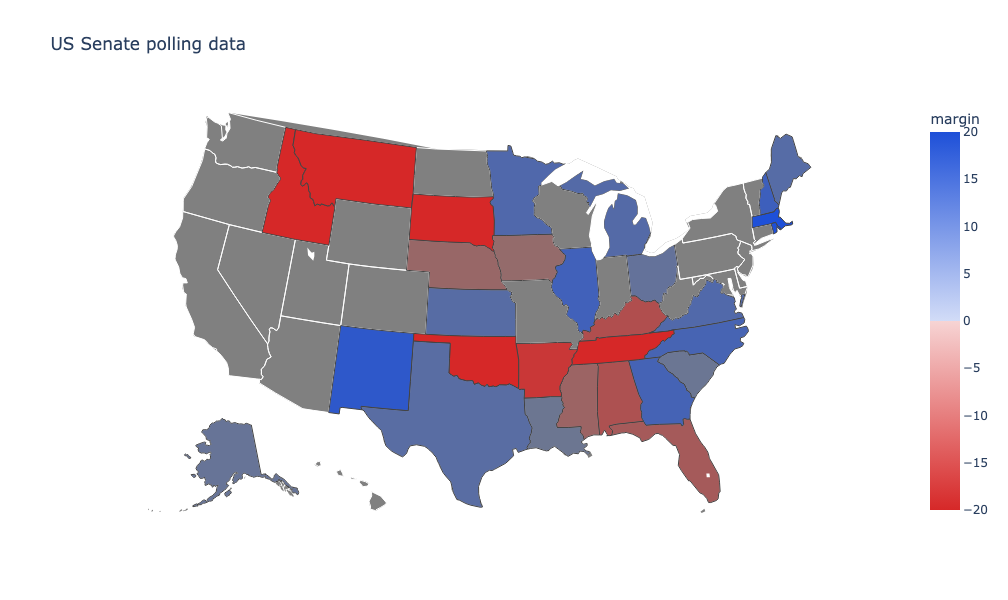

In [8]:
red = "214, 40, 40" # the rgb representation of "red"
blue = "30, 80, 216" # the rgb representation of "blue"

# we can define a color scale to represent our data using opacity. It will be a list of lists, which is expected by plotly.
color_scale = [
    [0.0, f"rgba({red}, 1)"], # 1 is most opaque for the "a" value of rgba color
    [0.5, f"rgba({red}, 0.2)"], # 0.2 will read as barely opaque
    [0.5, f"rgba({blue}, 0.2)"], # same thing for dem data
    [1.0, f"rgba({blue}, 1)"] #fully opaque and blue
]

color_bar = {
    "title":"Lead by margin",
    "tickvals":[-20, -10, 0, 10, 20],
    "ticktext": ["R+20", "R+10", "Tie" "D+10", "D+20"],
}

fig = px.choropleth(
    senate,
    locations="state", # tells plotly library which column of the data contains location information. There has to be a correlation between your location column and your geojson file. i.e., if you dataset uses zipcodes, your geojson will need a zipcode identifier for each region. US states are built in with plotly.
    locationmode="USA-states", # this mode is built in. It uses state abbreviations
    scope="usa", #zooms the map in on the us (visually)
    color="margin", # we are using the margin column to assign color to each region
    color_continuous_scale=color_scale,
    range_color=[-20, 20], # this should match whatever is in the legend
    height=600,
    title="US Senate polling data"
)

fig.update_geos(landcolor="grey") #for the states that don't have a race this year


### Homework
Select one data visualization method from the example galleries that is of interest to you, or that you might be interested in integrating into your project.

Bring the example code for the selected method into a Jupyter notebook and modify some of the parameters (around color, scale, input data, etc), documenting what you’ve changed in your comments.

In [18]:
# here I brought in the poems of Gerard Manley Hopkins from Project Gutenberg.
with open("../Final_Project/hopkins.txt", "r", encoding="utf-8") as file:
    book = file.read()

start = book.index("*** START OF")
end = book.index("*** END OF")

start = book.index("\n", start)

text = book[start:end]

print(len(book), "characters in the file,", len(text), "in the actual text")

108034 characters in the file, 89504 in the actual text


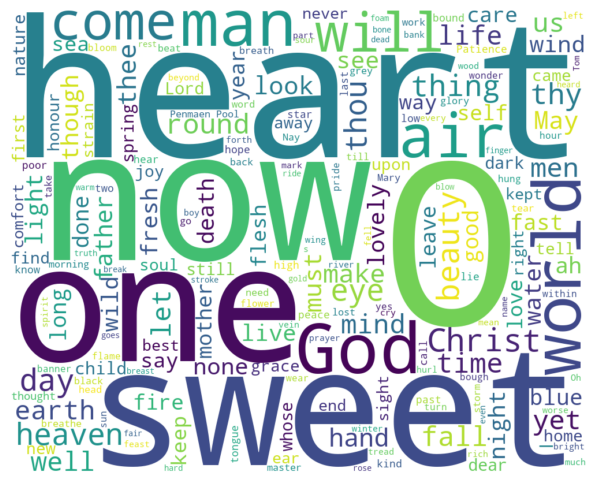

In [20]:
cloud = WordCloud(width=1000, height=800, background_color="white", random_state=1).generate(text) # I changed the dimensions here

plt.figure(figsize=(10, 6))                  # the size of the plot, in inches
plt.imshow(cloud, interpolation="bilinear")  # draw the cloud's image (bilinear smooths it)
plt.axis("off")                              # hide the plot's axes
plt.show()

[('o', 63), ('now', 57), ('d', 56), ('heart', 53), ('one', 45)]


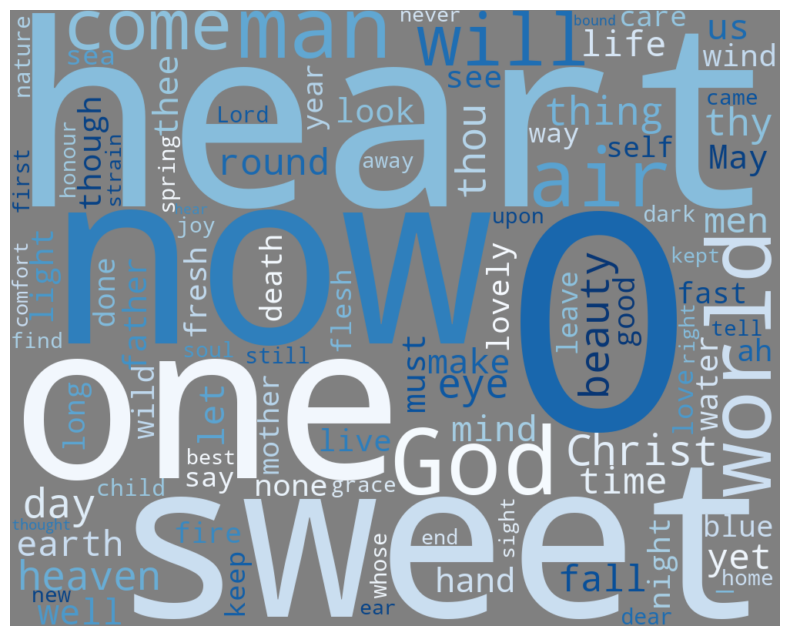

In [27]:
# STOPWORDS is a set, and | joins two sets together: the built-in stop words, plus a set of our own.
# Look at the first cloud, and add the words that are common but don't tell us much about this book
my_stopwords = STOPWORDS | {
    "the", "to", "of", "title", "index", "notes", "note", "appendix", "editor", "preface"
} # I changed these words

words = re.findall(r"[a-z']+", text.lower())

counts = pd.Series(words).value_counts()

counts = counts[~counts.index.isin(my_stopwords)]

word_counts = counts.head(100).to_dict()

print(list(word_counts.items())[:5])

cloud = WordCloud(
    width=1000, #changed
    height=800, # changed
    background_color="grey", #changed
    stopwords=my_stopwords,   
    colormap="Blues", # changed 
    max_words=100, # changed 
    random_state=1,
).generate(text)

plt.figure(figsize=(10, 8)) #changed
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

# save the most recent cloud as a PNG image, in this folder
cloud.to_file("hopkins_cloud.png") #changed title